In [2]:
%load_ext autoreload
%autoreload 2

# Imports
import sys; sys.path.append("..")
import time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.stats import mannwhitneyu
from skimage import measure
from skimage.feature import graycomatrix
from src.datos import cargar_inventario, a_gris, DATA
from src.preproceso import preprocesar, TAM
from src.segmentacion import umbral_adaptativo

## 1. Extracción de medidas por corte

In [3]:
# Inventario con las columnas del notebook: Ruta (relativa a DATA), Clase, Eje, Corte (número del archivo), IdNombre
inv = cargar_inventario()
base = pd.DataFrame({
    "Ruta": inv["ruta"].apply(lambda p: p.relative_to(DATA).as_posix()),
    "Clase": inv["Clase"],
    "Eje": inv["Corte"],
    "Corte": inv["N"],
    "IdNombre": inv["IdNombre"],
}).reset_index(drop=True)
print(len(base), "cortes")
base.groupby(["Clase", "Eje"]).size().unstack()

3427 cortes


Eje,Axial,Sagital
Clase,,
Control,1002,1014
MS,650,761


In [ ]:
# Medidas de un corte a partir de la máscara cerebral y la segmentación (ambas 256 x 256)
def medidas_corte(mask, seg):
    area_cerebro = int(mask.sum())
    lab = measure.label(seg, connectivity=2)          # conectividad 2: 8 vecinos
    areas = np.bincount(lab.ravel())[1:]              # área de cada región
    area_lesion = int(seg.sum())
    return {
        "Area_cerebro_px": area_cerebro,              # Área de la máscara del cerebro en píxeles
        "Frac_cerebro": area_cerebro / TAM ** 2,      # Cuánto de la imágen es cerebro
        "N_regiones": len(areas),                     # Número de regiones segmentadas
        "Area_lesion_px": area_lesion,                # Área de las regiones segmentadas en píxeles 
        "Area_rel": area_lesion / area_cerebro if area_cerebro else np.nan,   # Área de las regiones segmentadas relativa al cerebro
        "Area_media_region_px": float(areas.mean()) if len(areas) else 0.0,      # Media de las áreas de las regiones segmentadas (lesiones)
        "Area_max_region_px": int(areas.max()) if len(areas) else 0,             # Área máxima de las regiones segmentadas (lesiones)
    }

# Aplica el preprocesamiento completo a todos los cortes del inventario y devuelve un DataFrame con las medidas 
# de cada corte y una lista de errores
def extraer(inv, base):
    filas, errores = [], []
    for ruta_abs, (_, b) in zip(inv["ruta"], base.iterrows()):
        try:
            z, mask = preprocesar(ruta_abs)
            seg = umbral_adaptativo(z, mask)
            filas.append({**b.to_dict(), **medidas_corte(mask, seg)})
        except Exception as e:
            errores.append((b["Ruta"], repr(e)))
    return pd.DataFrame(filas), errores

In [10]:
# Prueba con una muestra chica antes de correr todo el dataset
muestra = base.sample(40, random_state=0)
t0 = time.time()
prueba, err_prueba = extraer(inv.loc[muestra.index], muestra)
dt = time.time() - t0
print(f"{len(prueba)} cortes en {dt:.1f} s ({dt / len(prueba):.3f} s por corte), {len(err_prueba)} errores")
print(f"Estimado para {len(base)} cortes: {dt / len(prueba) * len(base) / 60:.1f} min")
prueba.head()

40 cortes en 7.8 s (0.194 s por corte), 0 errores
Estimado para 3427 cortes: 11.1 min


,Ruta,Clase,Eje,Corte,IdNombre,Area_cerebro_px,Frac_cerebro,N_regiones,Area_lesion_px,Area_rel,Area_media_region,Area_max_region
0,Control Axial_crop/kontrol 14 (17).png,Control,Axial,17,14,20620,0.314636,0,0,0.000000,0.0,0
1,MS Saggital_crop/S1 (411).png,MS,Sagital,411,None,17445,0.266190,2,119,0.006821,59.5,68
2,Control Axial_crop/kontrol (4).png,Control,Axial,4,None,30487,0.465195,1,125,0.004100,125.0,125
3,Control Saggital_crop/kontrol 5 (21).png,Control,Sagital,21,5,6069,0.092606,0,0,0.000000,0.0,0
4,Control Axial_crop/kontrol 30 (7).png,Control,Axial,7,30,29057,0.443375,0,0,0.000000,0.0,0


In [61]:
# Extracción completa. Si el CSV ya existe se carga; si no, se calcula y se guarda (data/ no se sube a git)
CSV = Path("..") / "data" / "caracteristicas_cortes.csv"

if CSV.exists():
    feat = pd.read_csv(CSV)
    errores = []
    print("Cargado desde", CSV)
else:
    t0 = time.time()
    feat, errores = extraer(inv, base)
    print(f"Calculado en {(time.time() - t0) / 60:.1f} min")
    feat.to_csv(CSV, index=False)
    print("Guardado en", CSV)
print(len(feat), "filas,", len(errores), "errores")

Cargado desde ..\data\caracteristicas_cortes.csv
3427 filas, 0 errores


In [62]:
# Comprobación: que no falte ni sobre ningún corte
assert len(feat) == len(base), f"Faltan {len(base) - len(feat)} cortes"
assert feat["Ruta"].is_unique
assert set(feat["Ruta"]) == set(base["Ruta"])
print("Cortes con máscara vacía:", (feat["Area_cerebro_px"] == 0).sum())
print("Cortes sin ninguna región segmentada:", (feat["N_regiones"] == 0).sum())
feat.groupby(["Clase", "Eje"]).size().unstack()

Cortes con máscara vacía: 3
Cortes sin ninguna región segmentada: 2167


Eje,Axial,Sagital
Clase,,
Control,1002,1014
MS,650,761


In [63]:
feat.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Corte,3427.0,153.737,215.120,1.0,9.000,18.000,277.500,761.000
IdNombre,1867.0,24.122,13.908,1.0,12.000,24.000,36.000,49.000
Area_cerebro_px,3427.0,16261.672,8246.437,0.0,10828.500,14545.000,20914.000,43706.000
Frac_cerebro,3427.0,0.248,0.126,0.0,0.165,0.222,0.319,0.667
N_regiones,3427.0,0.739,1.287,0.0,0.000,0.000,1.000,10.000
Area_lesion_px,3427.0,96.760,206.813,0.0,0.000,0.000,95.500,1796.000
Area_rel,3424.0,0.005,0.012,0.0,0.000,0.000,0.005,0.114
Area_media_region_px,3427.0,46.011,86.768,0.0,0.000,0.000,73.000,1538.000
Area_max_region_px,3427.0,59.593,117.404,0.0,0.000,0.000,78.000,1538.000


&ensp; Se aplicó el pipeline completo (`preprocesar` → `umbral_adaptativo`) a los **3427 cortes** del inventario y se calcularon siete medidas por corte. Para el notebook se renombraron las columnas del inventario: `Eje` es la orientación (Axial/Sagital, que en `cargar_inventario()` se llama `Corte`), `Corte` es el número entre paréntesis del archivo y `Ruta` queda relativa a `DATA` para que el CSV sirva en cualquier computadora.

- **Medidas:** `Area_cerebro_px` (píxeles de la máscara a 256 × 256), `Frac_cerebro` (= `Area_cerebro` / 256²), `N_regiones` (componentes conexas de la segmentación con conectividad 2), `Area_lesion_px`, `Area_rel` (= `Area_lesion_px` / `Area_cerebro_px`), `Area_media_region_px` y `Area_max_region_px`. Si no hay regiones, el área media y la máxima valen 0.
- **Tiempo:** la prueba con 40 cortes dio 0,149 s por corte y la extracción completa tardó 9,9 min. No hubo errores.
- **Comprobación:** el CSV tiene una fila por cada archivo del inventario (3427), sin repetidos. Se guardó en `data/caracteristicas_cortes.csv`; como `data/` está en el `.gitignore`, cada integrante lo genera la primera vez que corre el notebook.

**Observaciones.** Tres cortes de MS axial (`A1 (284)`, `A1 (294)` y `A1 (320)`) tienen la máscara vacía: `mascara_cerebral` no encontró ninguna isla compacta, por lo que `Area_rel` queda en NaN. Además, 2179 de los 3427 cortes (63 %) no tienen ninguna región segmentada, lo que explica que la mediana de `N_regiones`, `Area_lesion_px` y `Area_rel` sea 0 en el dataset completo.

## 2. Descarte de cortes con poco cerebro

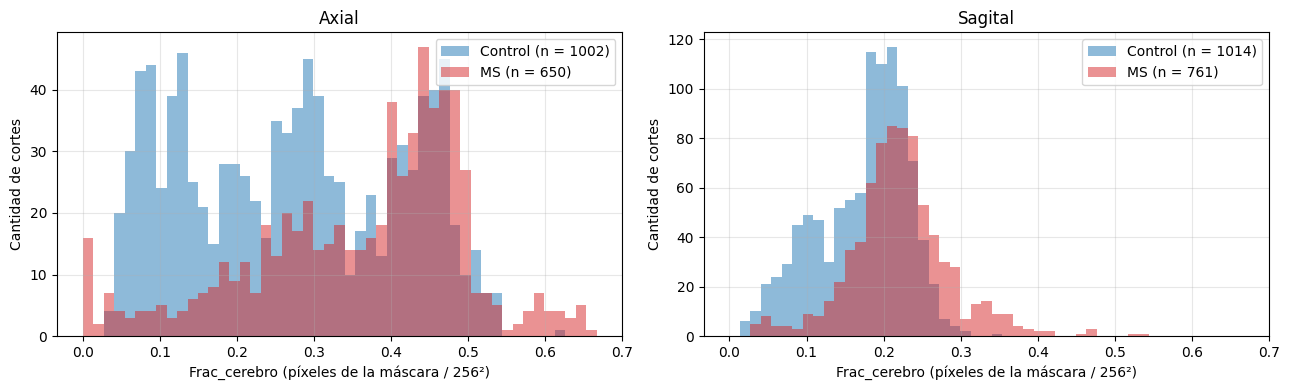

In [67]:
# Histograma de la fracción de cerebro por eje, separado por clase
bins = np.linspace(0, feat["Frac_cerebro"].max(), 50)
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, eje in zip(axs, ["Axial", "Sagital"]):
    for clase, color in [("Control", "tab:blue"), ("MS", "tab:red")]:
        v = feat.loc[(feat["Eje"] == eje) & (feat["Clase"] == clase), "Frac_cerebro"]
        ax.hist(v, bins=bins, alpha=0.5, color=color, label=f"{clase} (n = {len(v)})")
    ax.set_title(eje)
    ax.set_xlabel("Frac_cerebro (píxeles de la máscara / 256²)")
    ax.set_ylabel("Cantidad de cortes")
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

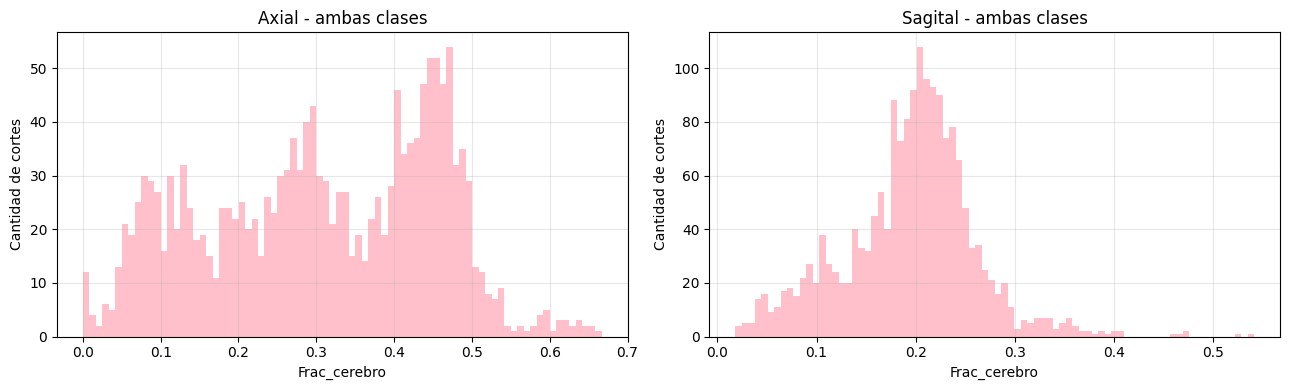

Axial percentiles 5/10/25/50: [0.067 0.091 0.188 0.309]
Sagital percentiles 5/10/25/50: [0.074 0.102 0.159 0.201]


In [68]:
# Histograma conjunto (MS + Control) por eje, con más resolución en la cola izquierda
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, eje in zip(axs, ["Axial", "Sagital"]):
    v = feat.loc[feat["Eje"] == eje, "Frac_cerebro"]
    ax.hist(v, bins=80, color="pink")
    ax.set_title(f"{eje} - ambas clases")
    ax.set_xlabel("Frac_cerebro")
    ax.set_ylabel("Cantidad de cortes")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

for eje in ["Axial", "Sagital"]:
    v = feat.loc[feat["Eje"] == eje, "Frac_cerebro"]
    print(eje, "percentiles 5/10/25/50:", np.percentile(v, [5, 10, 25, 50]).round(3))

In [69]:
# Conteo por intervalos de 0,02 para ubicar el valle entre la cola de cortes chicos y el grueso
bordes = np.arange(0, 0.32, 0.02)
tabla = pd.DataFrame({eje: np.histogram(feat.loc[feat["Eje"] == eje, "Frac_cerebro"], bins=bordes)[0]
                      for eje in ["Axial", "Sagital"]},
                     index=[f"{a:.2f}-{b:.2f}" for a, b in zip(bordes[:-1], bordes[1:])])
tabla.index.name = "Frac_cerebro"
tabla.T

Frac_cerebro,0.00-0.02,0.02-0.04,0.04-0.06,0.06-0.08,0.08-0.10,0.10-0.12,0.12-0.14,0.14-0.16,0.16-0.18,0.18-0.20,0.20-0.22,0.22-0.24,0.24-0.26,0.26-0.28,0.28-0.30
Axial,17,12,37,61,66,58,61,42,38,56,56,42,67,85,91
Sagital,2,17,39,49,66,91,76,112,172,241,313,248,151,79,47


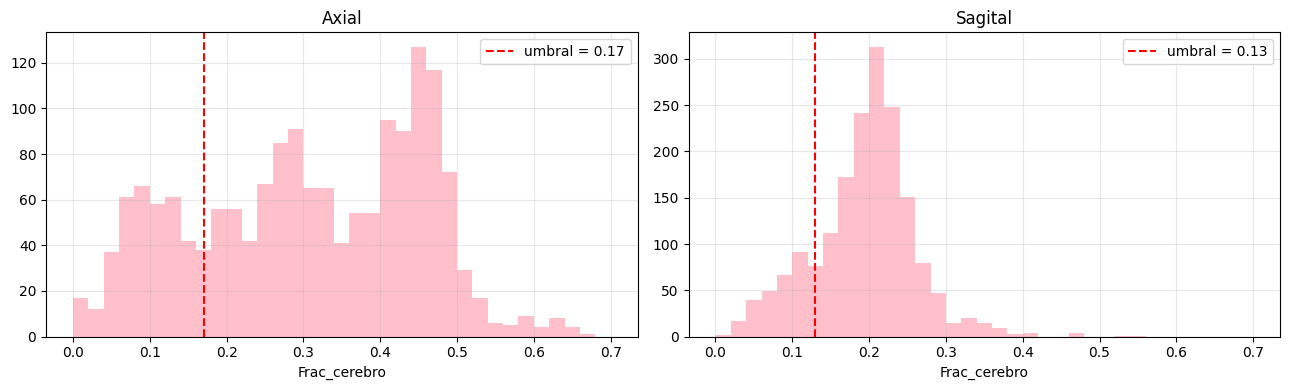

In [70]:
# Umbral de descarte por eje (el mismo para MS y Control): centro del intervalo del valle
UMBRAL_FRAC = {"Axial": 0.17, "Sagital": 0.13}
feat["Pasa"] = feat["Frac_cerebro"] >= feat["Eje"].map(UMBRAL_FRAC)

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, eje in zip(axs, ["Axial", "Sagital"]):
    ax.hist(feat.loc[feat["Eje"] == eje, "Frac_cerebro"], bins=bordes.tolist() + list(np.arange(0.32, 0.72, 0.02)), color="pink")
    ax.axvline(UMBRAL_FRAC[eje], color="r", ls="--", label=f"umbral = {UMBRAL_FRAC[eje]}")
    ax.set_title(eje)
    ax.set_xlabel("Frac_cerebro")
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [71]:
# Conteo de cortes que quedan y que se descartan, por Clase y por Eje
conteo = (feat.assign(Estado=np.where(feat["Pasa"], "Queda", "Descartado"))
              .groupby(["Clase", "Eje", "Estado"]).size().unstack(fill_value=0))
conteo["Total"] = conteo.sum(axis=1)
conteo["% descartado"] = (100 * conteo["Descartado"] / conteo["Total"]).round(1)
conteo

Estado           Descartado  Queda  Total  % descartado
Clase   Eje                                            
Control Axial           306    696   1002          30.5
        Sagital         243    771   1014          24.0
MS      Axial            65    585    650          10.0
        Sagital          51    710    761           6.7

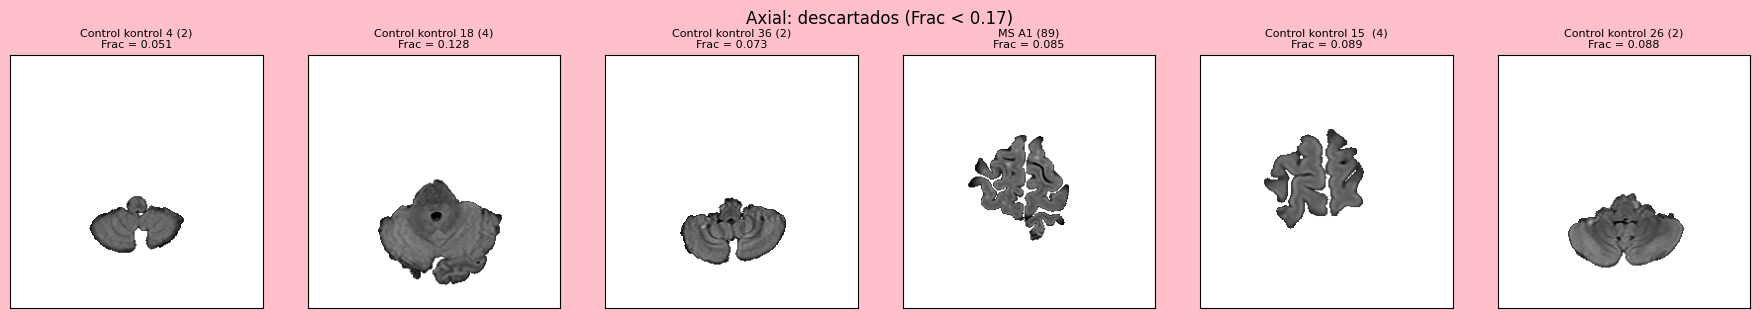

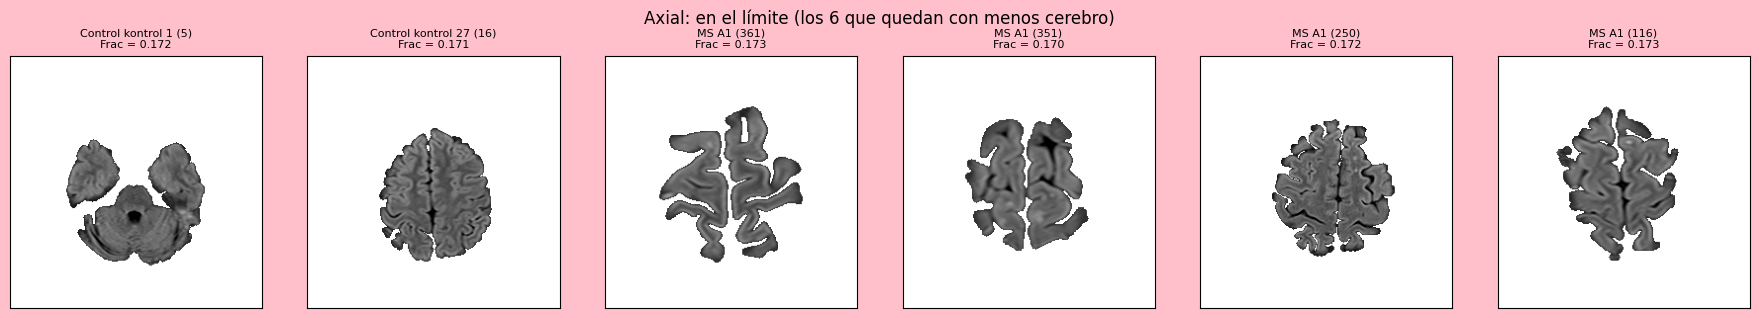

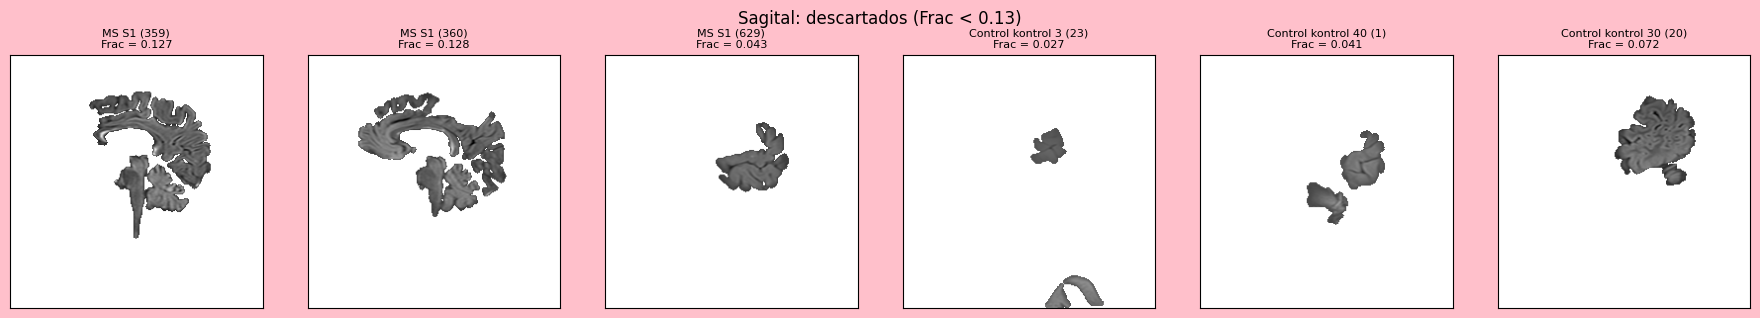

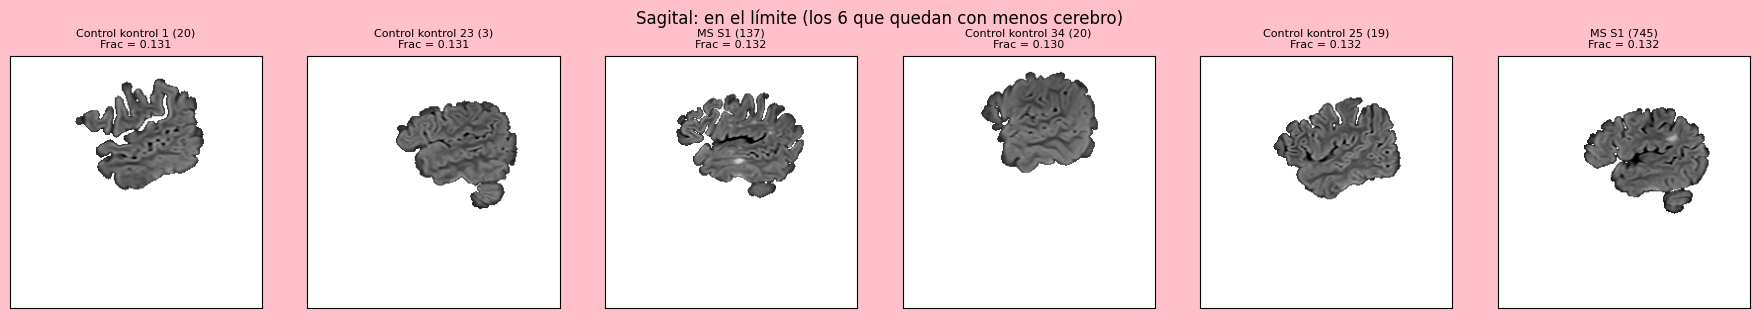

In [72]:
# Inspección visual: cortes descartados y cortes justo por encima del umbral
def mostrar_cortes(filas, titulo, n_col=6):
    n = len(filas)
    fig, axs = plt.subplots(int(np.ceil(n / n_col)), n_col, figsize=(3 * n_col, 3.2 * int(np.ceil(n / n_col))), facecolor = "pink")
    for ax in np.ravel(axs):
        #ax.axis("off")
        ax.set_xticks([])  # Borra los números y marcas del eje X
        ax.set_yticks([])
    for ax, (_, r) in zip(np.ravel(axs), filas.iterrows()):
        z, mask = preprocesar(DATA / r["Ruta"])
        ax.imshow(np.where(mask, z, np.nan), cmap="gray", vmin=-3, vmax=5)
        '''f mask.any():
            ax.contour(mask.astype(float), levels=[0.5], colors="y", linewidths=0.7)'''
        ax.set_title(f"{r['Clase']} {Path(r['Ruta']).stem}\nFrac = {r['Frac_cerebro']:.3f}", fontsize=8)
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

for eje in ["Axial", "Sagital"]:
    d = feat[feat["Eje"] == eje]
    u = UMBRAL_FRAC[eje]
    mostrar_cortes(d[~d["Pasa"]].sample(6, random_state=1), f"{eje}: descartados (Frac < {u})")
    limite = d[d["Pasa"]].nsmallest(6, "Frac_cerebro").sample(6, random_state=1)
    mostrar_cortes(limite, f"{eje}: en el límite (los 6 que quedan con menos cerebro)")

&ensp; Los cortes de los extremos de la cabeza (base de cráneo, fosa posterior y vértice) tienen poco cerebro, no son comparables con los cortes medios y generan falsos positivos. Se descartan con un umbral sobre `Frac_cerebro`, **uno por eje y el mismo para MS y Control**, para no introducir un sesgo por clase.

**Elección del umbral.** En los histogramas conjuntos, el grueso de los cortes axiales está por encima de 0,18 y el de los sagitales por encima de 0,14. El conteo por intervalos de 0,02 muestra un valle entre la cola izquierda y el grueso en **0,16–0,18 para axial** (38 cortes, frente a 61 en 0,12–0,14 y 56 en 0,18–0,20) y en **0,12–0,14 para sagital** (76 cortes, frente a 91 en 0,10–0,12 y 112 en 0,14–0,16). Se tomó el centro de cada valle: **0,17 para axial y 0,13 para sagital**.
<div align="center">

| Clase | Eje | Descartados | Quedan | Total | % descartado |
|---|---|---|---|---|---|
| Control | Axial | 306 | 696 | 1002 | 30,5 |
| Control | Sagital | 243 | 771 | 1014 | 24,0 |
| MS | Axial | 65 | 585 | 650 | 10,0 |
| MS | Sagital | 51 | 710 | 761 | 6,7 |

</div>

&ensp; Quedan 2762 cortes (1467 de Control y 1295 de MS). En la inspección visual, los axiales descartados son mayormente cortes de fosa posterior (cerebelo) y de vértice con pocas circunvoluciones, y los que quedan en el límite son cortes altos con los dos hemisferios completos o cortes bajos con lóbulos temporales y cerebelo. Los sagitales descartados son cortes laterales con islas sueltas de corteza.

**Limitaciones.**
- El umbral se determinó empíricamente a partir de la distribución observada: los histogramas no tienen un valle marcado (sobre todo en axial, donde la distribución de Control es multimodal) y un corrimiento de ±0,02 cambia la cantidad de descartados.
- **El descarte afecta mucho más a Control** (30,5 % y 24,0 %) que a MS (10,0 % y 6,7 %). Esto es coherente con que Control tiene más cortes por paciente (~15–24 contra ~9), que recorren más la cabeza, pero implica que los cortes que quedan de cada clase no están necesariamente a la misma altura.
- `Frac_cerebro` depende del recorte original de cada imagen (el lado mayor se lleva a 256 px), no del tamaño físico del cerebro, porque no se tiene el espaciado de píxel.
- Se descartan algunos sagitales mediales de MS con bastante cerebro pero fragmentados por la máscara (`S1 (359)`, `S1 (360)`), y entre los que quedan en el límite hay cortes con tejido extracerebral brillante dentro de la máscara (`kontrol 18 (3)`).

## 3. Verificación de la máscara cerebral

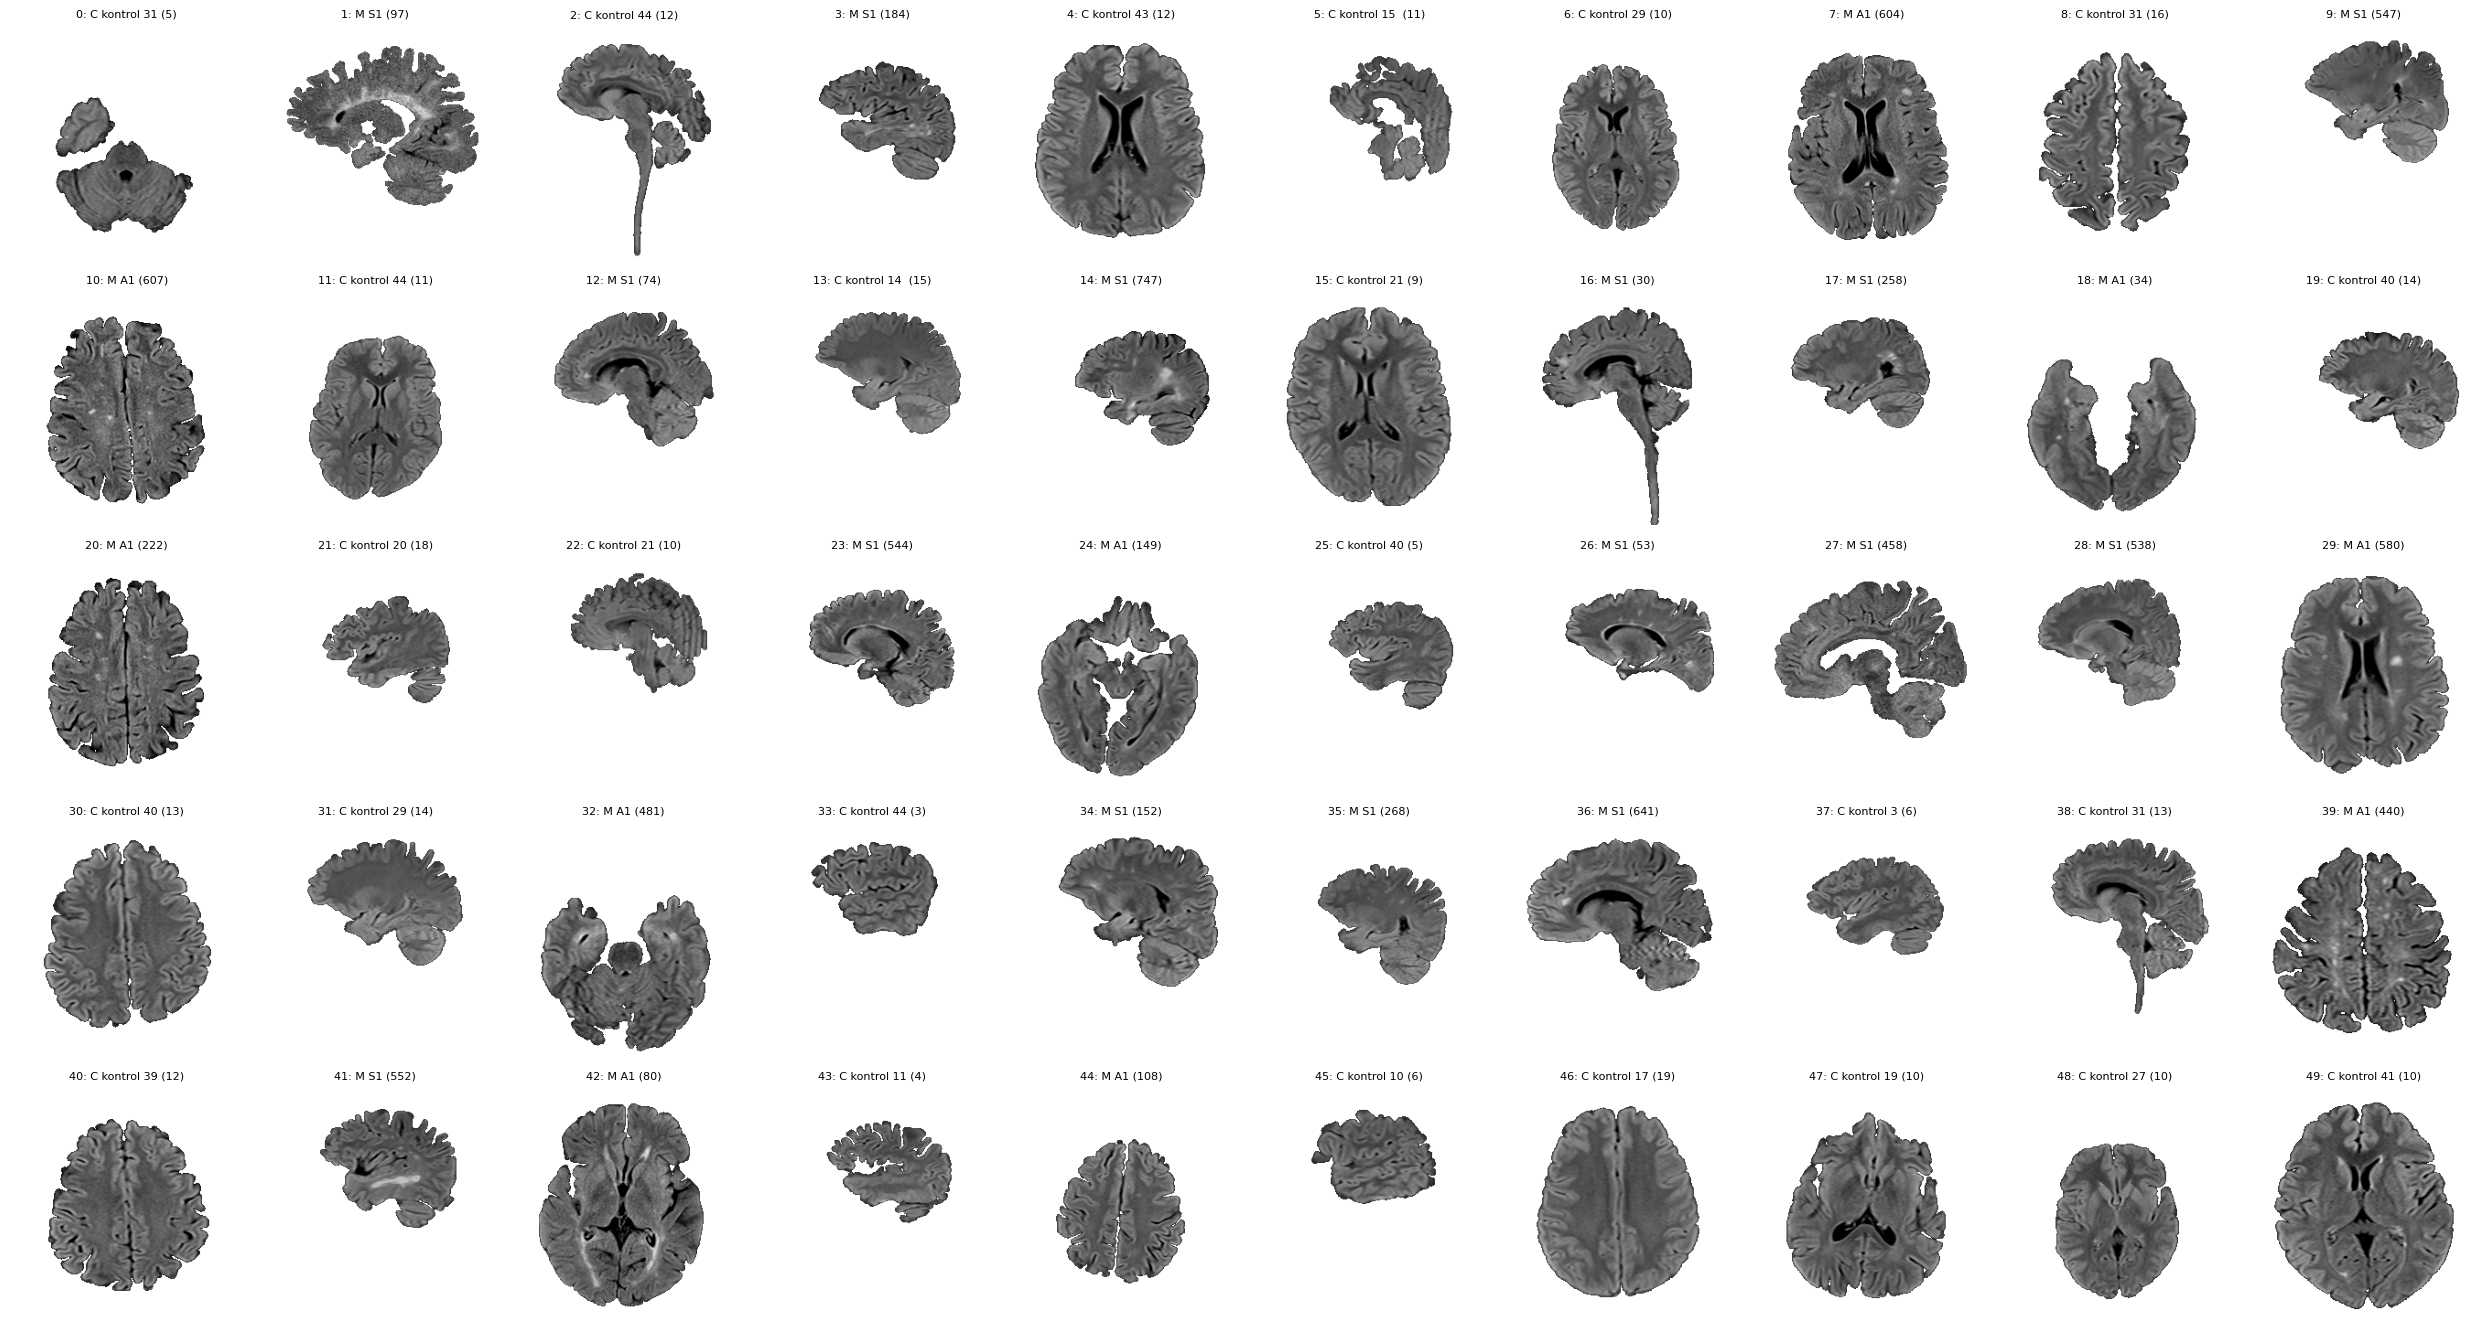

In [73]:
# 50 cortes al azar (semilla fija) entre los que pasaron el descarte, con la máscara superpuesta
verif = feat[feat["Pasa"]].sample(50, random_state=42).reset_index(drop=True)

fig, axs = plt.subplots(5, 10, figsize=(25, 13.5))
for i, (ax, (_, r)) in enumerate(zip(axs.ravel(), verif.iterrows())):
    z, mask = preprocesar(DATA / r["Ruta"])
    ax.imshow(np.where(mask, z, np.nan), cmap="gray", vmin=-3, vmax=5)
    #ax.contour(mask.astype(float), levels=[0.5], colors="y", linewidths=0.8)
    ax.set_title(f"{i}: {r['Clase'][0]} {Path(r['Ruta']).stem}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [74]:
# Anotación visual de la figura anterior. Categorías: "ok", "nasal" (tejido nasal u orbitario),
# "cuero" (anillo de cuero cabelludo), "hemisferio" (se perdió parte del cerebro),
# "medula" (la máscara sigue por la médula espinal, debajo del tronco). Los no listados son "ok".
ANOTACION = {
    2: "medula",
    16: "medula",
    38: "medula",
}

In [75]:
anot = verif[["Ruta", "Clase", "Eje"]].copy()
anot["Revision"] = [ANOTACION.get(i, "ok") for i in range(len(anot))]
print(anot["Revision"].value_counts())
print(f"\nTasa de error de la máscara: {100 * (anot['Revision'] != 'ok').mean():.0f} % ({(anot['Revision'] != 'ok').sum()} de {len(anot)})")
anot.groupby(["Eje", "Revision"]).size().unstack(fill_value=0)

Revision
ok        47
medula     3
Name: count, dtype: int64

Tasa de error de la máscara: 6 % (3 de 50)


Revision,medula,ok
Eje,,
Axial,0,22
Sagital,3,25


&ensp; Se revisaron visualmente 50 cortes elegidos al azar (semilla 42) entre los que pasaron el descarte (22 axiales y 28 sagitales), con la máscara superpuesta, y se anotó cada uno en una categoría: correcta, tejido nasal u orbitario, anillo de cuero cabelludo, hemisferio perdido o médula espinal incluida.

**Resultado.** 47 de 50 máscaras son correctas. En las 3 restantes (todas sagitales mediales: `kontrol 44 (12)`, `S1 (30)` y `kontrol 31 (13)`) la máscara sigue por la médula espinal debajo del tronco. Es un error menor, porque agrega poco área y es tejido nervioso, pero no es cerebro. **Tasa de error observada: 6 % (3 de 50).** En la muestra no apareció tejido nasal, cuero cabelludo ni hemisferios perdidos.

**Limitaciones.**
- Con 50 cortes, que no aparezca un tipo de error no significa que no exista. 
- La anotación es visual 

## 4. Comparación entre MS y Control

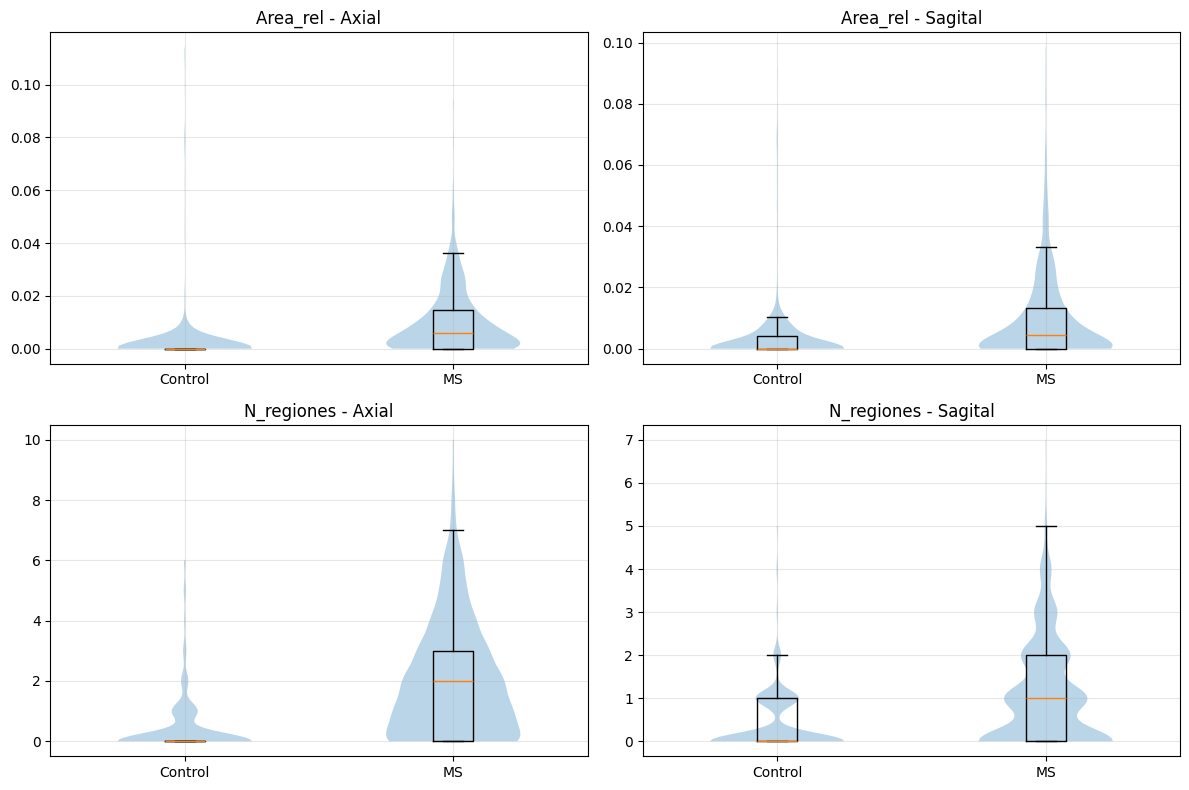

In [76]:
# Solo los cortes que pasaron el descarte
ok = feat[feat["Pasa"]].copy()
CARACT = ["Area_rel", "N_regiones", "Area_lesion_px", "Area_media_region_px", "Area_max_region_px"]

fig, axs = plt.subplots(2, 2, figsize=(12, 8))
for fila, c in enumerate(["Area_rel", "N_regiones"]):
    for col, eje in enumerate(["Axial", "Sagital"]):
        ax = axs[fila, col]
        datos_c = [ok.loc[(ok["Eje"] == eje) & (ok["Clase"] == k), c] for k in ["Control", "MS"]]
        ax.violinplot(datos_c, showextrema=False)
        ax.boxplot(datos_c, widths=0.15, showfliers=False)
        ax.set_xticks([1, 2], ["Control", "MS"])
        ax.set_title(f"{c} - {eje}")
        ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [77]:
# Mann-Whitney U (bilateral) entre MS y Control para cada característica y eje.
# CLES (common-language effect size) = U_MS / (n_MS * n_Control): probabilidad de que un corte de MS
# al azar tenga un valor mayor que uno de Control al azar (los empates cuentan 1/2). 0,5 = sin efecto.
def comparar(df, caract):
    filas = []
    for eje in ["Axial", "Sagital"]:
        for c in caract:
            ms = df.loc[(df["Eje"] == eje) & (df["Clase"] == "MS"), c].dropna()
            co = df.loc[(df["Eje"] == eje) & (df["Clase"] == "Control"), c].dropna()
            u, p = mannwhitneyu(ms, co, alternative="two-sided")
            filas.append({"Eje": eje, "Caracteristica": c, "n_MS": len(ms), "n_Control": len(co),
                          "Mediana_MS": ms.median(), "Mediana_Control": co.median(),
                          "Dif_medianas": ms.median() - co.median(),
                          "U": u, "p": p, "CLES": u / (len(ms) * len(co))})
    return pd.DataFrame(filas)

res = comparar(ok, CARACT)
res.style.format({"Mediana_MS": "{:.4g}", "Mediana_Control": "{:.4g}", "Dif_medianas": "{:.4g}",
                  "U": "{:.0f}", "p": "{:.2e}", "CLES": "{:.3f}"})

,Eje,Caracteristica,n_MS,n_Control,Mediana_MS,Mediana_Control,Dif_medianas,U,p,CLES
0,Axial,Area_rel,585,696,0.005908,0,0.005908,321244,4.27e-84,0.789
1,Axial,N_regiones,585,696,2,0,2,316369,4.25e-78,0.777
2,Axial,Area_lesion_px,585,696,153,0,153,321414,2.46e-84,0.789
3,Axial,Area_media_region_px,585,696,81.33,0,81.33,320780,1.89e-83,0.788
4,Axial,Area_max_region_px,585,696,96,0,96,322103,2.66e-85,0.791
5,Sagital,Area_rel,710,771,0.004316,0,0.004316,362686,1.30e-33,0.663
6,Sagital,N_regiones,710,771,1,0,1,361924,9.71e-34,0.661
7,Sagital,Area_lesion_px,710,771,62.5,0,62.5,364468,6.62e-35,0.666
8,Sagital,Area_media_region_px,710,771,57,0,57,358042,2.28e-30,0.654
9,Sagital,Area_max_region_px,710,771,59,0,59,360649,3.61e-32,0.659


In [78]:
# Control negativo: los controles no tienen lesiones, así que lo que se segmenta ahí son falsos positivos
filas = []
for eje in ["Axial", "Sagital"]:
    for clase in ["Control", "MS"]:
        d = ok[(ok["Eje"] == eje) & (ok["Clase"] == clase)]
        p25, p50, p75, p90, p95 = np.percentile(d["Area_rel"], [25, 50, 75, 90, 95])
        filas.append({"Eje": eje, "Clase": clase, "n": len(d),
                      "% cortes con alguna región": 100 * (d["N_regiones"] > 0).mean(),
                      "Area_rel P25": p25, "Mediana": p50, "P75": p75, "P90": p90, "P95": p95,
                      "N_regiones mediana": d["N_regiones"].median()})
fp = pd.DataFrame(filas)
fp.style.format({c: "{:.4f}" for c in ["Area_rel P25", "Mediana", "P75", "P90", "P95"]}
               | {"% cortes con alguna región": "{:.1f}"})

,Eje,Clase,n,% cortes con alguna región,Area_rel P25,Mediana,P75,P90,P95,N_regiones mediana
0,Axial,Control,696,23.6,0.0000,0.0000,0.0000,0.0037,0.0070,0.000000
1,Axial,MS,585,72.8,0.0000,0.0059,0.0146,0.0270,0.0331,2.000000
2,Sagital,Control,771,28.8,0.0000,0.0000,0.0041,0.0081,0.0110,0.000000
3,Sagital,MS,710,55.8,0.0000,0.0043,0.0133,0.0274,0.0389,1.000000


&ensp; Se compararon las cinco medidas de la segmentación entre MS y Control, por eje, solo con los cortes que pasaron el descarte (axial: 585 MS y 696 Control; sagital: 710 MS y 771 Control). Se usó el test de **Mann-Whitney U** bilateral porque las distribuciones son muy asimétricas y con muchos ceros. Como tamaño de efecto se reporta el *common-language effect size* (CLES = U / (n_MS · n_Control)), que es la probabilidad de que un corte de MS al azar tenga un valor mayor que uno de Control al azar (0,5 = sin diferencia).
<div align="center">

| Eje | Característica | Mediana MS | Mediana Control | p | CLES |
|---|---|---|---|---|---|
| Axial | Area_rel | 0,0059 | 0 | 4,3 × 10⁻⁸⁴ | 0,787 |
| Axial | N_regiones | 2 | 0 | 4,2 × 10⁻⁷⁸ | 0,777 |
| Axial | Area_max_region_px | 96 | 0 | 2,7 × 10⁻⁸⁵ | 0,791 |
| Sagital | Area_rel | 0,0043 | 0 | 1,3 × 10⁻³³ | 0,663 |
| Sagital | N_regiones | 1 | 0 | 9,7 × 10⁻³⁴ | 0,661 |
| Sagital | Area_max_region_px | 59 | 0 | 3,6 × 10⁻³² | 0,659 |

</div>

&ensp; Todas las medidas son mayores en MS. El efecto es **mayor en axial** (CLES ≈ 0,78–0,79) que en sagital (CLES ≈ 0,65–0,67). `Area_lesion` y `Area_media_region_px` dan prácticamente lo mismo que `Area_rel` (CLES entre 0,654 y 0,789), así que aportan poca información nueva.

**Control negativo (tasa de falsos positivos).** Los controles no tienen lesiones, por lo que todo lo que el método segmenta en ellos es un falso positivo. Tiene alguna región segmentada el **23 % de los cortes axiales de Control** y el **28,5 % de los sagitales de control**. La mediana de `Area_rel` en Control es 0 en ambos ejes; el percentil 90 es 0,0037 (axial) y 0,0081 (sagital), y el 95 es 0,0070 y 0,0110. En MS tiene alguna región el 72,8 % (axial) y el 55,8 % (sagital) de los cortes. Esto significa que una parte de lo que se mide en MS también son falsos positivos, del mismo orden que en Control, y que el método no puede asegurar que un corte individual tiene lesiones.

**Advertencia sobre la inferencia (pseudorreplicación).** Los cortes de un mismo paciente **no son independientes**: comparten anatomía, adquisición y carga lesional. El test los trata como observaciones independientes, por lo que los p-valores están muy sobreestimados en significancia; el n efectivo se acerca al número de pacientes (72 y 59), no al de cortes. En MS no hay ID de paciente, así que no se puede agregar por paciente para corregirlo. **Es la limitación principal de esta comparación** porque los p-valores no deben interpretarse literalmente, y los tamaños de efecto son más informativos.

**Otras limitaciones.** El descarte fue asimétrico entre clases (4.2), por lo que los cortes de cada clase pueden estar a alturas distintas de la cabeza. Además, MS y Control podrían venir de adquisiciones diferentes (el dataset no lo informa), y eso también podría generar diferencias en la segmentación que no se deban a la enfermedad.

## 5. Textura de la sustancia blanca

In [82]:
# Región de análisis: interior profundo de la máscara (a más de 10 px del borde, como en la prueba 3
# del notebook 03) sin los píxeles segmentados como lesión
D_PROFUNDA = 10
NIVELES = 32
Z_RANGO = (-2.0, 6.0)
PX_MIN_REGION = 200      # si la región es más chica, la textura del corte queda en NaN
ANGULOS = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]

def region_profunda(mask, seg, d_min=D_PROFUNDA):
    return (ndi.distance_transform_edt(mask) > d_min) & ~seg

def glcm_features(z, region, niveles=NIVELES, z_rango=Z_RANGO, px_min=PX_MIN_REGION):
    nombres = ["Contraste", "Homogeneidad", "Energia", "Correlacion", "Entropia"]
    if region.sum() < px_min:
        return {n: np.nan for n in nombres}
    zmin, zmax = z_rango
    q = (np.clip((z - zmin) / (zmax - zmin), 0, 0.9999) * niveles).astype(np.uint8)
    q[~region] = niveles                                   # nivel extra para lo que está fuera de la región
    g = graycomatrix(q, distances=[1], angles=ANGULOS, levels=niveles + 1, symmetric=True)
    P = g[:niveles, :niveles, 0, :].sum(axis=-1).astype(float)   # se descarta el nivel extra y se suman los ángulos
    P /= P.sum()
    i, j = np.indices(P.shape)
    mu_i, mu_j = (P * i).sum(), (P * j).sum()
    sd_i = np.sqrt((P * (i - mu_i) ** 2).sum())
    sd_j = np.sqrt((P * (j - mu_j) ** 2).sum())
    nz = P[P > 0]
    return {
        "Contraste": float((P * (i - j) ** 2).sum()),
        "Homogeneidad": float((P / (1 + (i - j) ** 2)).sum()),
        "Energia": float((P ** 2).sum()),
        "Correlacion": float((P * (i - mu_i) * (j - mu_j)).sum() / (sd_i * sd_j)) if sd_i * sd_j > 0 else np.nan,
        "Entropia": float(-(nz * np.log2(nz)).sum()),
    }

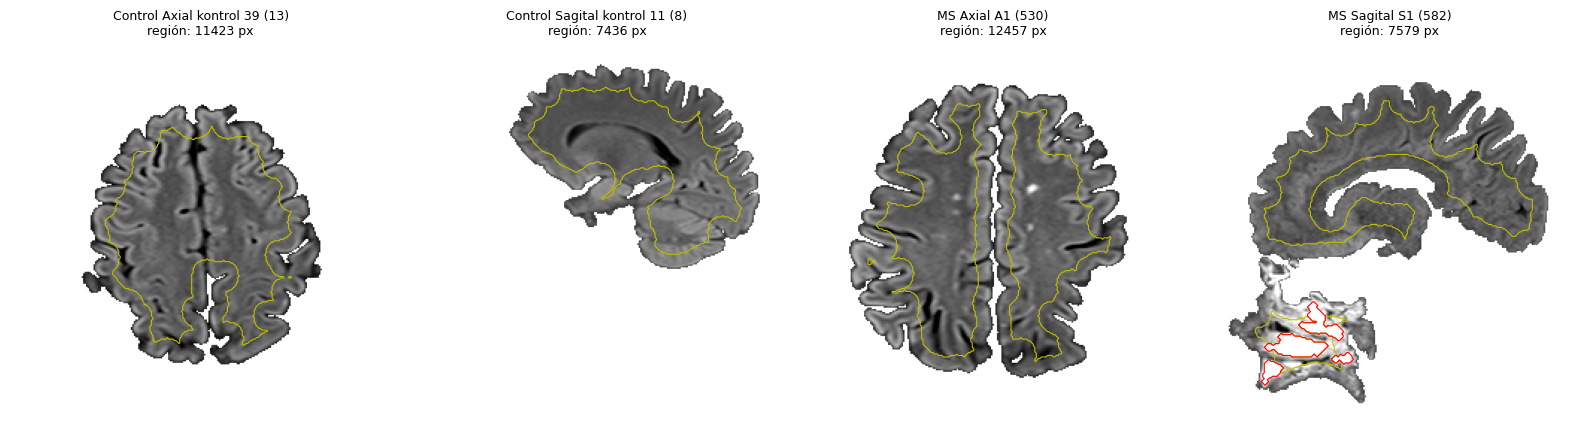

In [83]:
# Región de análisis sobre 4 cortes de ejemplo (verde: región profunda; rojo: segmentación)
ejemplos = ok.groupby(["Clase", "Eje"]).sample(1, random_state=3)
fig, axs = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, (_, r) in zip(axs, ejemplos.iterrows()):
    z, mask = preprocesar(DATA / r["Ruta"])
    seg = umbral_adaptativo(z, mask)
    reg = region_profunda(mask, seg)
    ax.imshow(np.where(mask, z, np.nan), cmap="gray", vmin=-3, vmax=5)
    ax.contour(reg.astype(float), levels=[0.5], colors="y", linewidths=0.8)
    if seg.any():
        ax.contour(seg.astype(float), levels=[0.5], colors="r", linewidths=0.8)
    ax.set_title(f"{r['Clase']} {r['Eje']} {Path(r['Ruta']).stem}\nregión: {reg.sum()} px", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [85]:
# Textura de todos los cortes. Se agrega al mismo CSV (si ya tiene las columnas, se cargan)
TEXT = ["Contraste", "Homogeneidad", "Energia", "Correlacion", "Entropia"]

if all(c in feat.columns for c in TEXT):
    print("Textura ya presente en", CSV)
else:
    t0 = time.time()
    rows = []
    for ruta in feat["Ruta"]:
        z, mask = preprocesar(DATA / ruta)
        seg = umbral_adaptativo(z, mask)
        rows.append(glcm_features(z, region_profunda(mask, seg)))
    feat = pd.concat([feat, pd.DataFrame(rows, index=feat.index)], axis=1)
    feat.to_csv(CSV, index=False)
    print(f"Calculado en {(time.time() - t0) / 60:.1f} min y guardado en {CSV}")

print("Cortes con textura NaN (región < PX_MIN_REGION):", feat[TEXT[0]].isna().sum(),
      "| de ellos pasan el descarte:", feat.loc[feat["Pasa"], TEXT[0]].isna().sum())
ok = feat[feat["Pasa"]].copy()

Textura ya presente en ..\data\caracteristicas_cortes.csv
Cortes con textura NaN (región < PX_MIN_REGION): 94 | de ellos pasan el descarte: 2


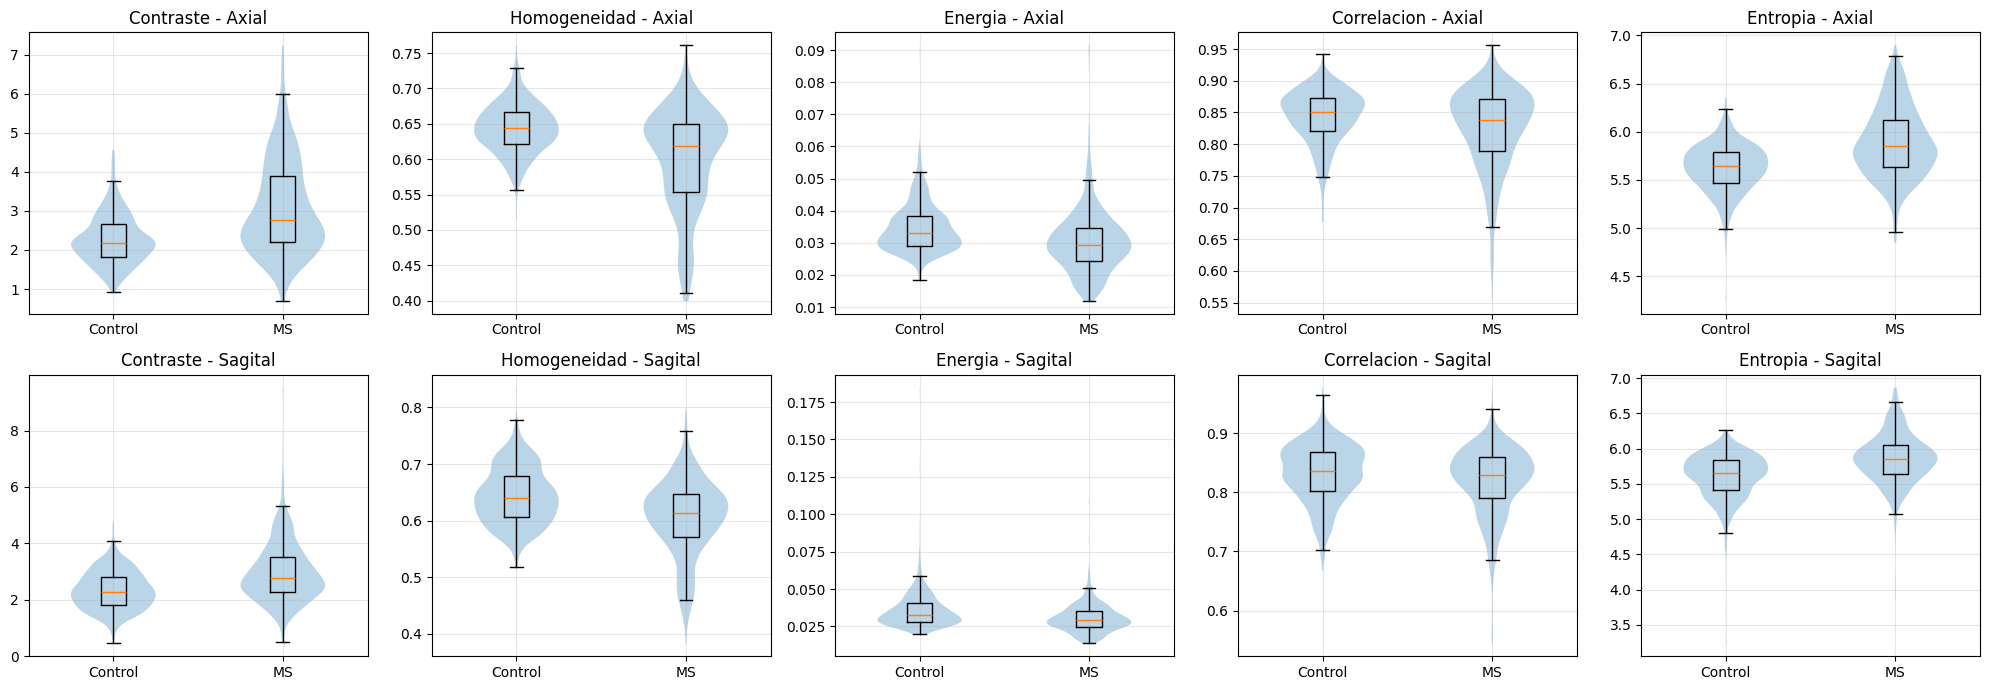

In [86]:
fig, axs = plt.subplots(2, 5, figsize=(20, 7))
for fila, eje in enumerate(["Axial", "Sagital"]):
    for col, c in enumerate(TEXT):
        ax = axs[fila, col]
        datos_c = [ok.loc[(ok["Eje"] == eje) & (ok["Clase"] == k), c].dropna() for k in ["Control", "MS"]]
        ax.violinplot(datos_c, showextrema=False)
        ax.boxplot(datos_c, widths=0.15, showfliers=False)
        ax.set_xticks([1, 2], ["Control", "MS"])
        ax.set_title(f"{c} - {eje}")
        ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [87]:
res_text = comparar(ok, TEXT)
res_text.style.format({"Mediana_MS": "{:.4g}", "Mediana_Control": "{:.4g}", "Dif_medianas": "{:.4g}",
                       "U": "{:.0f}", "p": "{:.2e}", "CLES": "{:.3f}"})

,Eje,Caracteristica,n_MS,n_Control,Mediana_MS,Mediana_Control,Dif_medianas,U,p,CLES
0,Axial,Contraste,584,696,2.776,2.181,0.595,288535,2.35e-38,0.710
1,Axial,Homogeneidad,584,696,0.6186,0.6439,-0.02524,128698,1.11e-29,0.317
2,Axial,Energia,584,696,0.02948,0.0331,-0.003622,136821,6.64e-24,0.337
3,Axial,Correlacion,584,696,0.8385,0.8509,-0.0124,174602,1.38e-05,0.430
4,Axial,Entropia,584,696,5.85,5.644,0.206,290351,6.24e-40,0.714
5,Sagital,Contraste,709,771,2.762,2.283,0.4786,373605,2.76e-34,0.683
6,Sagital,Homogeneidad,709,771,0.6131,0.6399,-0.02681,186079,2.37e-26,0.340
7,Sagital,Energia,709,771,0.02927,0.03299,-0.003716,190988,1.20e-23,0.349
8,Sagital,Correlacion,709,771,0.8297,0.8359,-0.006231,239841,4.58e-05,0.439
9,Sagital,Entropia,709,771,5.855,5.653,0.2018,383296,6.98e-41,0.701


&ensp; La región de análisis es el interior profundo de la máscara (píxeles a más de 10 px del borde, como en la prueba 3 del notebook 03) sin los píxeles segmentados como lesión, con la idea de quedarse mayormente con sustancia blanca. Sobre esa región se calculó una GLCM simétrica (distancia 1, 4 ángulos acumulados, 32 niveles de z entre −2 y 6). Solo cuentan los pares de píxeles con ambos extremos dentro de la región: lo de afuera se lleva a un nivel extra que después se descarta. Se extrajeron contraste, homogeneidad, energía (suma de P², igual que en el notebook 03), correlación y entropía **por corte**. Si la región tiene menos de 200 px, la textura queda en NaN: pasa en 94 cortes, de los cuales solo 2 pasaron el descarte por umbral de frac_cerebro.

&ensp; En el notebook 03 la textura **no sirvió para segmentar** lesiones, porque k-means separaba estructuras dominantes y no tejido lesionado. Acá se usa como **característica global del corte**, para ver si la sustancia blanca de MS es en conjunto más heterogénea que la de Control.

<div align="center">

| Eje | Característica | Mediana MS | Mediana Control | p | CLES |
|---|---|---|---|---|---|
| Axial | Contraste | 2,776 | 2,181 | 2,4 × 10⁻³⁸ | 0,710 |
| Axial | Homogeneidad | 0,619 | 0,644 | 1,1 × 10⁻²⁹ | 0,317 |
| Axial | Energía | 0,0295 | 0,0331 | 6,6 × 10⁻²⁴ | 0,337 |
| Axial | Correlación | 0,839 | 0,851 | 1,4 × 10⁻⁵ | 0,430 |
| Axial | Entropía | 5,850 | 5,644 | 6,2 × 10⁻⁴⁰ | 0,714 |
| Sagital | Contraste | 2,762 | 2,283 | 2,8 × 10⁻³⁴ | 0,684 |
| Sagital | Homogeneidad | 0,613 | 0,640 | 2,4 × 10⁻²⁶ | 0,340 |
| Sagital | Energía | 0,0293 | 0,0330 | 1,2 × 10⁻²³ | 0,349 |
| Sagital | Correlación | 0,830 | 0,836 | 4,6 × 10⁻⁵ | 0,439 |
| Sagital | Entropía | 5,855 | 5,653 | 7,0 × 10⁻⁴¹ | 0,701 |

</div>

&ensp; En ambos ejes, la región profunda de MS tiene **más contraste y más entropía** (CLES ≈ 0,68–0,71) y **menos homogeneidad y energía** (CLES ≈ 0,32–0,35, es decir, ~0,65–0,68 a favor de Control). En otras palabras, en MS la intensidad es más heterogénea. La correlación casi no separa las clases (CLES ≈ 0,43–0,44). El tamaño de efecto de la textura es menor que el de la segmentación en axial y parecido en sagital.

**Limitaciones.**
- La región profunda **no es solo sustancia blanca**: no hay atlas, e incluye ventrículos, núcleos grises y, en sagital, tronco y cerebelo.
- La región **puede contener lesiones que la segmentación no marcó** (por ejemplo, las hiperintensidades visibles de `A1 (530)` en la figura de ejemplo). Por eso, parte de la diferencia de textura puede deberse a las propias lesiones y no a cambios difusos de la sustancia blanca.
- Los errores de máscara también pasan a la textura: en `S1 (582)` hay tejido facial dentro de la región.
- Valen las mismas advertencias de 4.4: pseudorreplicación (p-valores sobreestimados), descarte asimétrico entre clases y posibles diferencias de adquisición entre grupos, a las que la textura es especialmente sensible.